In [1]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split

In [10]:
dataset = load_wine(as_frame=True)
X = dataset.data
y = dataset.target

In [18]:
print(type(X))
print(type(y))
print(X.shape)
print(y.shape)


print("\nMissing values per feature:")
print(X.isna().sum())

print("\nFeature statistics:")
print(X.describe().round(2))

print("\nClass distribution:")
print(y.value_counts())

print("\nFirst 5 rows of the target variable:")
print(y.head())

print("First 5 rows of the dataset:")
print(X.head())

<class 'pandas.DataFrame'>
<class 'pandas.Series'>
(178, 13)
(178,)

Missing values per feature:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Feature statistics:
       alcohol  malic_acid     ash  alcalinity_of_ash  magnesium  \
count   178.00      178.00  178.00             178.00     178.00   
mean     13.00        2.34    2.37              19.49      99.74   
std       0.81        1.12    0.27               3.34      14.28   
min      11.03        0.74    1.36              10.60      70.00   
25%      12.36        1.60    2.21              17.20      88.00   
50%      13.05     

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [24]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

baseline_model = DummyClassifier(strategy='most_frequent')
baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_test)

# print("Baseline Model Accuracy:", accuracy_score(y_test, y_pred))
# print("\nConfusion Matrix:")
# print(confusion_matrix(y_test, y_pred))
# print("\nClassification Report:")
# print(classification_report(y_test, y_pred))

print("Predicted classes:", y_pred)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

Predicted classes: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Test accuracy: 0.3888888888888889
Confusion matrix:
 [[ 0 14  0]
 [ 0 14  0]
 [ 0  8  0]]


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

# Chain preprocessing and classification into one model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000),
)

model.fit(X_train, y_train)

# Predict classes
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

# Evaluate
print("Training accuracy:",
      accuracy_score(y_train, train_predictions))

print("Test accuracy:",
      accuracy_score(y_test, test_predictions))

print("Confusion matrix:\n",
      confusion_matrix(y_test, test_predictions))

# Examine the first five predictions
print("\nActual classes:", y_test.iloc[:5].to_numpy())
print("Predicted classes:", test_predictions[:5])

# Each row contains probabilities for classes 0, 1, and 2
print("\nClass order:", model.classes_)
print("Class probabilities:\n",
      model.predict_proba(X_test.iloc[:5]).round(3))

Training accuracy: 1.0
Test accuracy: 1.0
Confusion matrix:
 [[14  0  0]
 [ 0 14  0]
 [ 0  0  8]]

Actual classes: [0 0 2 0 1]
Predicted classes: [0 0 2 0 1]

Class order: [0 1 2]
Class probabilities:
 [[0.998 0.001 0.001]
 [0.996 0.001 0.004]
 [0.009 0.038 0.953]
 [0.995 0.004 0.   ]
 [0.003 0.996 0.001]]


In [26]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_validate

# Define how to create the five folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

# Fit and evaluate a fresh copy of the pipeline for each fold
results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    return_train_score=True,
)

train_scores = results["train_score"]
validation_scores = results["test_score"]

for fold, (train_score, validation_score) in enumerate(
    zip(train_scores, validation_scores),
    start=1,
):
    print(
        f"Fold {fold}: "
        f"train={train_score:.3f}, "
        f"validation={validation_score:.3f}"
    )

print(f"\nMean validation accuracy: {validation_scores.mean():.3f}")
print(f"Standard deviation: {validation_scores.std():.3f}")

Fold 1: train=1.000, validation=1.000
Fold 2: train=1.000, validation=0.897
Fold 3: train=1.000, validation=1.000
Fold 4: train=1.000, validation=1.000
Fold 5: train=1.000, validation=0.964

Mean validation accuracy: 0.972
Standard deviation: 0.040


In [27]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

models = {
    "Logistic regression": model,
    "KNN (k=5)": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5),
    ),
}

for name, candidate in models.items():
    scores = cross_validate(
        candidate,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        return_train_score=True,
    )

    print(f"\n{name}")
    print(f"Mean training accuracy: {scores['train_score'].mean():.3f}")
    print(
        "Validation accuracies:",
        scores["test_score"].round(3),
    )
    print(
        f"Mean validation accuracy: "
        f"{scores['test_score'].mean():.3f}"
    )
    print(f"Standard deviation: {scores['test_score'].std():.3f}")


Logistic regression
Mean training accuracy: 1.000
Validation accuracies: [1.    0.897 1.    1.    0.964]
Mean validation accuracy: 0.972
Standard deviation: 0.040

KNN (k=5)
Mean training accuracy: 0.979
Validation accuracies: [0.966 0.966 0.929 0.929 0.964]
Mean validation accuracy: 0.950
Standard deviation: 0.018


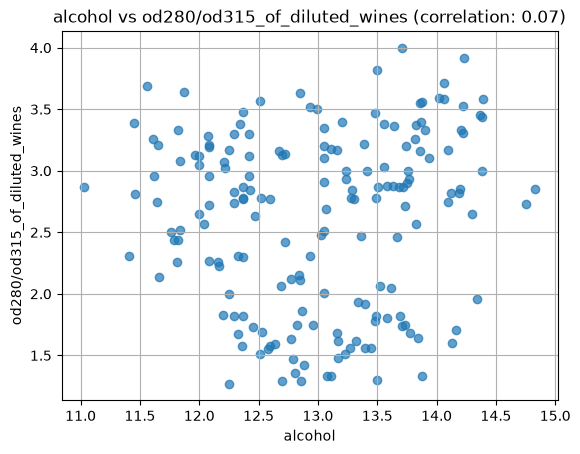

In [ ]:
import matplotlib.pyplot as plt

x_col = X.columns[0]  
y_col = X.columns[11]  


correlation = X[x_col].corr(X[y_col])

plt.scatter(X[x_col], X[y_col], alpha=0.7)
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.title(f"{x_col} vs {y_col} (correlation: {correlation:.2f})")
plt.grid(True)
plt.show()

In [32]:
import pandas as pd
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(
    estimator=model,
    param_grid={
        "logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100],
    },
    scoring="accuracy",
    cv=cv,
    return_train_score=True,
    refit=True,
)

search.fit(X_train, y_train)

results = pd.DataFrame(search.cv_results_)

print(
    results[
        [
            "param_logisticregression__C",
            "mean_train_score",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ].round(4).to_string(index=False)
)

print("\nBest settings:", search.best_params_)
print("Best mean validation accuracy:", search.best_score_)

best_model = search.best_estimator_

 param_logisticregression__C  mean_train_score  mean_test_score  std_test_score  rank_test_score
                       0.001            0.7131           0.7108          0.0432                6
                       0.010            0.9877           0.9579          0.0336                5
                       0.100            0.9947           0.9862          0.0276                1
                       1.000            1.0000           0.9722          0.0403                2
                      10.000            1.0000           0.9722          0.0403                2
                     100.000            1.0000           0.9650          0.0378                4

Best settings: {'logisticregression__C': 0.1}
Best mean validation accuracy: 0.9862068965517242
